# Model Improvement and Validation

This notebook checks the saved Random Forest baseline, tunes a separate candidate using training data only, and compares both models on the same held-out split. The primary selection metric is macro F1 because the irrigation classes are imbalanced; accuracy and per-class precision/recall are also reported.

The baseline was trained on the 80/20 split created with `random_state=42` and no stratification. The split below deliberately reproduces that contract so the saved baseline and candidate are compared on the same unseen rows. Stratified 5-fold cross-validation is used inside the training portion only.

In [1]:
from pathlib import Path
import sys

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)

RANDOM_STATE = 42
TARGET_COLUMN = "Irrigation_Need"
print("Python executable:", sys.executable)
print("Libraries imported; random state:", RANDOM_STATE)

Python executable: G:\AIOT\smart-irrigation\.venv\Scripts\python.exe
Libraries imported; random state: 42


In [2]:
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "irrigation_prediction_processed.csv"
BASELINE_MODEL_PATH = PROJECT_ROOT / "models" / "irrigation_model.joblib"
OPTIMIZED_MODEL_PATH = PROJECT_ROOT / "models" / "irrigation_model_optimized.joblib"

for required_path in (DATA_PATH, BASELINE_MODEL_PATH):
    if not required_path.is_file():
        raise FileNotFoundError(f"Required project artifact not found: {required_path}")

data = pd.read_csv(DATA_PATH)
existing_model = joblib.load(BASELINE_MODEL_PATH)

if TARGET_COLUMN not in data.columns:
    raise ValueError(f"Target column {TARGET_COLUMN!r} is missing from {DATA_PATH}")
if data.empty:
    raise ValueError("The processed dataset is empty.")
if data[TARGET_COLUMN].isna().any():
    raise ValueError("The target contains missing values; resolve these before training.")

print("Project root:", PROJECT_ROOT)
print("Processed dataset:", DATA_PATH.name, data.shape)
print("Baseline artifact:", BASELINE_MODEL_PATH.name, type(existing_model).__name__)
print("Optimized artifact will be saved separately:", OPTIMIZED_MODEL_PATH.name)
display(data.head())

Project root: G:\AIOT\smart-irrigation
Processed dataset: irrigation_prediction_processed.csv (10000, 20)
Baseline artifact: irrigation_model.joblib RandomForestClassifier
Optimized artifact will be saved separately: irrigation_model_optimized.joblib


,Soil_Type,Soil_pH,Soil_Moisture,Organic_Carbon,Electrical_Conductivity,Temperature_C,Humidity,Rainfall_mm,Sunlight_Hours,Wind_Speed_kmh,Crop_Type,Crop_Growth_Stage,Season,Irrigation_Type,Water_Source,Field_Area_hectare,Mulching_Used,Previous_Irrigation_mm,Region,Irrigation_Need
0,Clay,6.14,36.48,0.42,2.17,21.90,31.19,1167.70,4.01,1.97,Wheat,Vegetative,Rabi,Rainfed,Reservoir,4.73,Yes,1.98,South,Low
1,Silt,6.41,50.56,0.38,0.23,36.50,26.01,831.28,10.72,16.82,Maize,Flowering,Zaid,Canal,Groundwater,12.22,Yes,33.56,Central,Medium
2,Sandy,7.71,40.07,1.09,2.18,41.83,76.41,1844.45,7.75,19.03,Cotton,Harvest,Rabi,Drip,Reservoir,5.52,Yes,34.62,South,Low
3,Clay,5.96,12.75,1.56,0.40,37.22,43.32,306.26,8.90,11.44,Wheat,Sowing,Kharif,Canal,Reservoir,1.43,Yes,84.03,North,Medium
4,Clay,7.76,18.58,0.95,2.52,22.38,86.44,1875.63,10.39,11.26,Cotton,Sowing,Zaid,Canal,River,2.52,No,60.86,South,Medium


In [3]:
print("Missing values in dataset:", int(data.isna().sum().sum()))
print("Target distribution (count and proportion):")
target_distribution = pd.DataFrame(
    {
        "count": data[TARGET_COLUMN].value_counts(),
        "proportion": data[TARGET_COLUMN].value_counts(normalize=True),
    }
).sort_index()
display(target_distribution)

# Keep the feature contract consistent with the saved baseline model.
X = data.drop(columns=[TARGET_COLUMN]).select_dtypes(include="number")
y = data[TARGET_COLUMN]
model_feature_names = getattr(existing_model, "feature_names_in_", None)
if model_feature_names is not None:
    missing_features = set(model_feature_names).difference(X.columns)
    extra_features = set(X.columns).difference(model_feature_names)
    if missing_features or extra_features:
        raise ValueError(
            "Numeric input columns do not match the baseline model. "
            f"Missing: {sorted(missing_features)}; extra: {sorted(extra_features)}"
        )
    X = X.loc[:, list(model_feature_names)]
elif X.shape[1] != existing_model.n_features_in_:
    raise ValueError(
        f"Baseline expects {existing_model.n_features_in_} features, got {X.shape[1]}"
    )

print(f"Model input: {X.shape[1]} numeric features")
print("Categorical columns are not encoded because the existing baseline was trained on numeric features only:")
print(data.drop(columns=[TARGET_COLUMN]).select_dtypes(exclude="number").columns.tolist())

Missing values in dataset: 0
Target distribution (count and proportion):


,count,proportion
Irrigation_Need,,
High,336,0.0336
Low,5864,0.5864
Medium,3800,0.3800


Model input: 11 numeric features
Categorical columns are not encoded because the existing baseline was trained on numeric features only:
['Soil_Type', 'Crop_Type', 'Crop_Growth_Stage', 'Season', 'Irrigation_Type', 'Water_Source', 'Mulching_Used', 'Region']


## Fixed hold-out split

Do not use the test rows for fitting or hyperparameter selection. This unstratified split intentionally matches the split used to create `irrigation_model.joblib`; stratification is applied to cross-validation folds within `X_train`.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
)

print(f"Training rows: {len(X_train):,}; held-out rows: {len(X_test):,}")
print("Training class counts:", y_train.value_counts().sort_index().to_dict())
print("Held-out class counts:", y_test.value_counts().sort_index().to_dict())
assert len(X_train) + len(X_test) == len(data)
assert X_train.index.intersection(X_test.index).empty

Training rows: 8,000; held-out rows: 2,000
Training class counts: {'High': 277, 'Low': 4660, 'Medium': 3063}
Held-out class counts: {'High': 59, 'Low': 1204, 'Medium': 737}


## Baseline verification

The following evaluates the existing serialized baseline on its original training rows and the reconstructed held-out rows. The train score is diagnostic, not a generalization estimate.

In [5]:
def classification_metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_weighted": f1_score(y_true, y_pred, average="weighted", zero_division=0),
    }

baseline_train_predictions = existing_model.predict(X_train)
baseline_test_predictions = existing_model.predict(X_test)
baseline_train_metrics = classification_metrics(y_train, baseline_train_predictions)
baseline_test_metrics = classification_metrics(y_test, baseline_test_predictions)

baseline_scores = pd.DataFrame(
    [
        {"split": "train", **baseline_train_metrics},
        {"split": "held-out test", **baseline_test_metrics},
    ]
).set_index("split")
display(baseline_scores.style.format("{:.3f}"))

print("Baseline held-out classification report:")
print(classification_report(y_test, baseline_test_predictions, zero_division=0))

,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted
split,,,,,
train,1.000,1.000,1.000,1.000,1.000
held-out test,0.728,0.699,0.571,0.607,0.722


Baseline held-out classification report:
              precision    recall  f1-score   support

        High       0.68      0.29      0.40        59
         Low       0.77      0.83      0.80      1204
      Medium       0.64      0.59      0.61       737

    accuracy                           0.73      2000
   macro avg       0.70      0.57      0.61      2000
weighted avg       0.72      0.73      0.72      2000



## Cross-validation and tuning

Five-fold stratified cross-validation runs only on `X_train` and `y_train`. The search selects by mean macro F1, so the rare `High` class has equal weight to `Low` and `Medium`; the held-out test data is not passed to either cross-validation or search.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy", "f1_macro": "f1_macro"}

baseline_cv_results = cross_validate(
    existing_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
    n_jobs=1,
)
baseline_cv_summary = {
    "train_f1_macro_mean": baseline_cv_results["train_f1_macro"].mean(),
    "validation_f1_macro_mean": baseline_cv_results["test_f1_macro"].mean(),
    "validation_f1_macro_std": baseline_cv_results["test_f1_macro"].std(),
    "validation_accuracy_mean": baseline_cv_results["test_accuracy"].mean(),
}
print("Baseline stratified CV summary (training data only):")
display(pd.Series(baseline_cv_summary).to_frame("score").style.format("{:.3f}"))

Baseline stratified CV summary (training data only):


,score
train_f1_macro_mean,1.000
validation_f1_macro_mean,0.606
validation_f1_macro_std,0.016
validation_accuracy_mean,0.733


In [7]:
parameter_distributions = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", 0.7, 1.0],
    "class_weight": [None, "balanced_subsample"],
}

search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    param_distributions=parameter_distributions,
    n_iter=12,
    scoring=scoring,
    cv=cv,
    refit="f1_macro",
    random_state=RANDOM_STATE,
    n_jobs=1,
    return_train_score=True,
    verbose=1,
)
search.fit(X_train, y_train)
optimized_model = search.best_estimator_

print("Best mean CV macro F1:", f"{search.best_score_:.4f}")
print("Best parameters:")
display(pd.Series(search.best_params_, name="value").to_frame())

Fitting 5 folds for each of 12 candidates, totalling 60 fits


Best mean CV macro F1: 0.6468
Best parameters:


,value
n_estimators,300
min_samples_split,10
min_samples_leaf,4
max_features,sqrt
max_depth,30
class_weight,balanced_subsample


## Held-out comparison and error analysis

After hyperparameters are selected, evaluate the refitted candidate once on the untouched held-out split. Macro metrics and per-class results are included to avoid treating accuracy as the sole measure of success.

In [8]:
optimized_train_predictions = optimized_model.predict(X_train)
optimized_test_predictions = optimized_model.predict(X_test)
optimized_train_metrics = classification_metrics(y_train, optimized_train_predictions)
optimized_test_metrics = classification_metrics(y_test, optimized_test_predictions)

comparison = pd.DataFrame(
    [
        {"model": "Baseline Random Forest", **baseline_train_metrics, **{f"test_{k}": v for k, v in baseline_test_metrics.items()}},
        {"model": "Optimized Random Forest", **optimized_train_metrics, **{f"test_{k}": v for k, v in optimized_test_metrics.items()}},
    ]
).set_index("model")
display(comparison.style.format("{:.3f}"))

cv_comparison = pd.DataFrame(
    [
        {
            "model": "Baseline Random Forest",
            "CV train macro F1": baseline_cv_results["train_f1_macro"].mean(),
            "CV validation macro F1": baseline_cv_results["test_f1_macro"].mean(),
            "CV validation std": baseline_cv_results["test_f1_macro"].std(),
            "CV validation accuracy": baseline_cv_results["test_accuracy"].mean(),
        },
        {
            "model": "Optimized Random Forest",
            "CV train macro F1": search.cv_results_["mean_train_f1_macro"][search.best_index_],
            "CV validation macro F1": search.best_score_,
            "CV validation std": search.cv_results_["std_test_f1_macro"][search.best_index_],
            "CV validation accuracy": search.cv_results_["mean_test_accuracy"][search.best_index_],
        },
    ]
).set_index("model")
display(cv_comparison.style.format("{:.3f}"))

print("Optimized held-out classification report:")
print(classification_report(y_test, optimized_test_predictions, zero_division=0))

class_labels = sorted(y.unique())
baseline_confusion = pd.DataFrame(
    confusion_matrix(y_test, baseline_test_predictions, labels=class_labels),
    index=class_labels,
    columns=class_labels,
)
optimized_confusion = pd.DataFrame(
    confusion_matrix(y_test, optimized_test_predictions, labels=class_labels),
    index=class_labels,
    columns=class_labels,
)
print("Baseline confusion matrix (rows = actual; columns = predicted):")
display(baseline_confusion)
print("Optimized confusion matrix (rows = actual; columns = predicted):")
display(optimized_confusion)

macro_f1_change = optimized_test_metrics["f1_macro"] - baseline_test_metrics["f1_macro"]
print(f"Held-out macro F1 change: {macro_f1_change:+.4f}")
if macro_f1_change > 0:
    print("The optimized candidate improved held-out macro F1; inspect per-class recall and CV stability before deployment.")
elif macro_f1_change < 0:
    print("The optimized candidate did not improve held-out macro F1; retain the baseline unless other requirements justify a change.")
else:
    print("The candidate tied the baseline on held-out macro F1; there is no demonstrated macro-F1 improvement.")

,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro,test_f1_weighted
model,,,,,,,,,,
Baseline Random Forest,1.000,1.000,1.000,1.000,1.000,0.728,0.699,0.571,0.607,0.722
Optimized Random Forest,0.940,0.899,0.960,0.926,0.941,0.722,0.627,0.654,0.639,0.724


,CV train macro F1,CV validation macro F1,CV validation std,CV validation accuracy
model,,,,
Baseline Random Forest,1.000,0.606,0.016,0.733
Optimized Random Forest,0.929,0.647,0.017,0.731


Optimized held-out classification report:
              precision    recall  f1-score   support

        High       0.46      0.54      0.50        59
         Low       0.80      0.78      0.79      1204
      Medium       0.62      0.64      0.63       737

    accuracy                           0.72      2000
   macro avg       0.63      0.65      0.64      2000
weighted avg       0.73      0.72      0.72      2000



Baseline confusion matrix (rows = actual; columns = predicted):


,High,Low,Medium
High,17,0,42
Low,0,1005,199
Medium,8,295,434


Optimized confusion matrix (rows = actual; columns = predicted):


,High,Low,Medium
High,32,0,27
Low,0,944,260
Medium,38,231,468


Held-out macro F1 change: +0.0316
The optimized candidate improved held-out macro F1; inspect per-class recall and CV stability before deployment.


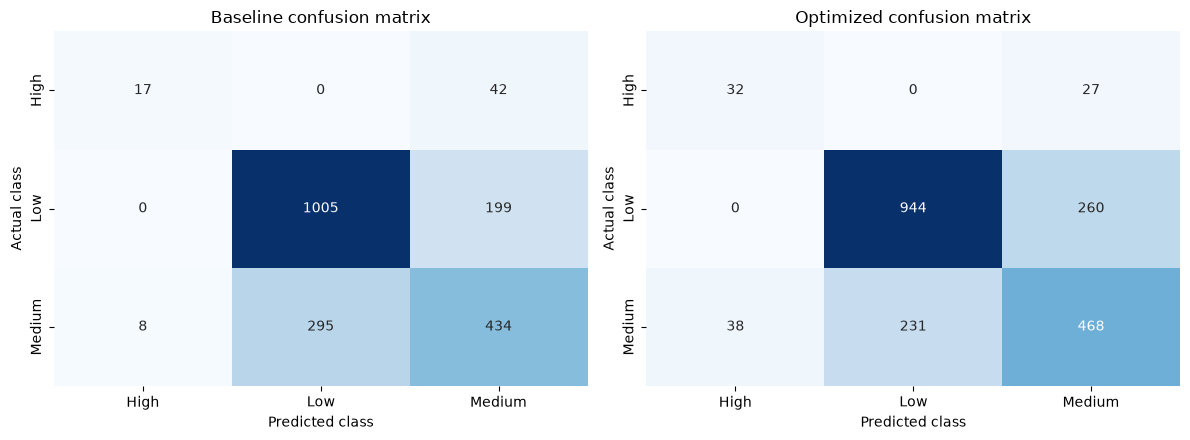

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for axis, matrix, title in zip(
    axes,
    (baseline_confusion, optimized_confusion),
    ("Baseline", "Optimized"),
):
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axis)
    axis.set_title(f"{title} confusion matrix")
    axis.set_xlabel("Predicted class")
    axis.set_ylabel("Actual class")
plt.tight_layout()
plt.show()

## Save and verify the candidate

The optimized candidate is saved to a new artifact; the original baseline is not overwritten. Reloading and checking predictions confirms the saved artifact preserves the fitted model.

In [10]:
OPTIMIZED_MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(optimized_model, OPTIMIZED_MODEL_PATH)
reloaded_optimized_model = joblib.load(OPTIMIZED_MODEL_PATH)
reloaded_predictions = reloaded_optimized_model.predict(X_test)
assert (reloaded_predictions == optimized_test_predictions).all()

print("Optimized artifact saved and reloaded successfully:", OPTIMIZED_MODEL_PATH)
print("Held-out predictions match after reload:", bool((reloaded_predictions == optimized_test_predictions).all()))
print("Original baseline artifact remains unchanged:", BASELINE_MODEL_PATH.is_file())

Optimized artifact saved and reloaded successfully: G:\AIOT\smart-irrigation\models\irrigation_model_optimized.joblib
Held-out predictions match after reload: True
Original baseline artifact remains unchanged: True


## Interpretation and limitations

- Use the held-out and cross-validation macro F1, class-specific recall, confusion matrices, and train-validation gaps together. A higher accuracy alone is not evidence of a better irrigation classifier.
- This comparison reproduces the baseline's original numeric-only feature set and unstratified hold-out split. Categorical sensor/context fields are intentionally not encoded here to keep the baseline comparison and downstream input contract consistent.
- The available data is a single processed CSV without an independent site, season, or time-based test set. Random splits therefore do not establish robustness to new farms or future conditions. Confirm that inputs such as `Previous_Irrigation_mm` are available before the irrigation decision and are not post-outcome leakage.
- The reported hold-out score is one fixed-split estimate. Deployment readiness requires domain validation, monitoring, and confirmation on representative real sensor data; this notebook does not deploy or control irrigation hardware.